# M5 Forecasting — Part 1 · Statistical models
## Notebook 02 · Stationarity & model identification

**Owner:** Calvin · **Previous:** `01_full_EDA.ipynb` · **Next:** `03_arima_sarima.ipynb`

In notebook 01 I learned *how* sales behave (trend, strong weekly pattern, milder yearly pattern). Now I want to translate that into the numbers ARIMA needs: **`(p, d, q)(P, D, Q)ₛ`**.

### The map of this notebook

| Step | Question | Gives me |
|---|---|---|
| 0 | Which series, which data? | `ts_train` (locked test set) |
| 1 | What does "stationary" mean, and why does ARIMA care? | the goal of steps 2–4 |
| 2 | Does the size of the wiggles grow with the level? | the **transformation** (log or not) |
| 3 | Is the series stationary as it is? (ADF & KPSS tests) | whether I need to difference |
| 4 | Which differencing makes it stationary? | **`d`** and **`D`** (and `s = 7`) |
| 5 | What do the ACF / PACF of the stationary series look like? | **`p, q, P, Q`** candidates |
| 6 | Do the 3 states behave the same? | whether one recipe works for all |
| 7 | Summary | the candidate list for notebook 03 |

### A reminder of the notation (I'll explain each letter when I get to it)

`SARIMA(p, d, q)(P, D, Q)ₛ`

| Letter | Plain English | Found in step |
|---|---|---|
| `d` | how many times I take "today − yesterday" | 4 |
| `D` | how many times I take "today − same day last week" | 4 |
| `s` | the length of the seasonal cycle (7 days) | already known from notebook 01 |
| `p` / `q` | how many recent days (AR) / recent surprises (MA) the model uses | 5 |
| `P` / `Q` | same, but at weekly lags (7, 14, 21… days ago) | 5 |

## 0 · Setup and data

I start from the file I exported at the end of notebook 01, so I don't need to reload the 120 MB raw csv.

**Which series?** The **total** is my main series (cleanest trend and seasonality, notebook 01 §5). I also check the **3 states** at the end, because they are the natural level for SNAP later.

In [1]:
import warnings
warnings.filterwarnings("ignore")          # statsmodels prints a lot of warnings for KPSS p-values

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

DATA_DIR = Path("data_processed")

# Same colours and chart style as notebooks 00 and 01
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, INK2 = "#9a9893", "#0b0b0b", "#52514e"
STATE_COLORS = {"CA": BLUE, "TX": ORANGE, "WI": AQUA}

plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 1.4,
})
pd.set_option("display.width", 160)

In [2]:
# --- Step 1: read the aggregated daily series from notebook 01 ---
df_daily_agg = pd.read_csv(DATA_DIR / "m5_daily_aggregates.csv", parse_dates=["date"], index_col="date")
print("df_daily_agg:", df_daily_agg.shape)
print("Columns I will use:", ["total", "state_CA", "state_TX", "state_WI", "is_christmas", "is_test"])


# --- Step 2: fix Christmas (same function as notebook 01) ---
def fix_christmas(ts):
    # Replace each 25 December by the mean of (same weekday -7 days, +7 days).
    ts_fixed = ts.astype(float).copy()
    for day in ts.index[(ts.index.month == 12) & (ts.index.day == 25)]:
        before = ts.get(day - pd.Timedelta(days=7))
        after = ts.get(day + pd.Timedelta(days=7))
        ts_fixed[day] = np.mean([before, after])
    return ts_fixed

ts_total_clean = fix_christmas(df_daily_agg["total"])


# --- Step 3: split train / test and LOCK the test set ---
# Golden rule: every decision in this notebook (log or not, d, D, p, q...) is made on the TRAIN part only.
# If I looked at the test period to choose the model, my final score would be too optimistic (= data leakage).
is_test = df_daily_agg["is_test"] == 1
ts_train = ts_total_clean[~is_test]
ts_test = ts_total_clean[is_test]

print(f"\nts_train: {ts_train.index[0].date()} -> {ts_train.index[-1].date()}  ({len(ts_train)} days)")
print(f"ts_test : {ts_test.index[0].date()} -> {ts_test.index[-1].date()}  ({len(ts_test)} days)  <- not touched until notebook 03")

df_daily_agg: (1941, 43)
Columns I will use: ['total', 'state_CA', 'state_TX', 'state_WI', 'is_christmas', 'is_test']

ts_train: 2011-01-29 -> 2016-04-24  (1913 days)
ts_test : 2016-04-25 -> 2016-05-22  (28 days)  <- not touched until notebook 03


## 1 · What is "stationary", and why does ARIMA care?

**The plain-English picture.** Imagine you cut the series into pieces, e.g. one piece from 2012 and one from 2015, hide the dates, and give them to a friend. If the friend **cannot tell which piece is older**, the series is stationary: same average level, same size of wiggles, same "rhythm" between one day and the next.

Our sales are clearly **not** like that: the 2015 piece sits higher (trend), so anyone can tell them apart.

**The formal version** (lecture 4, *Stationary processes*): a series $Y_t$ is (weakly) stationary if

1. the mean $E[Y_t] = \mu$ is the same for every $t$,
2. the variance $Var(Y_t) = \sigma^2$ is the same for every $t$,
3. the covariance between $Y_t$ and $Y_{t-k}$ depends only on the gap $k$, not on $t$.

**Why ARIMA needs it.** ARMA estimates *one* set of coefficients (e.g. "today = 0.5 × yesterday + noise") for the whole history. That only makes sense if the rules are the same in 2012 and in 2015. So the recipe is:

> **make the series stationary** (transform + difference) → **fit an ARMA on it** → **undo the differencing** to get forecasts in units.

The "I" in ARIMA (*Integrated*) is exactly the "undo the differencing" part. Steps 2–4 do the first arrow.

## 2 · Do the wiggles grow with the level? → log transformation

If the daily ups and downs get **bigger when sales get bigger**, the variance is not constant (condition 2 above is broken). Differencing does not fix that. A **log** does, because it turns "+20 % on Saturday" into a constant shift, whatever the level.

**My check:** compute the mean and the standard deviation for each month, and see if they move together.

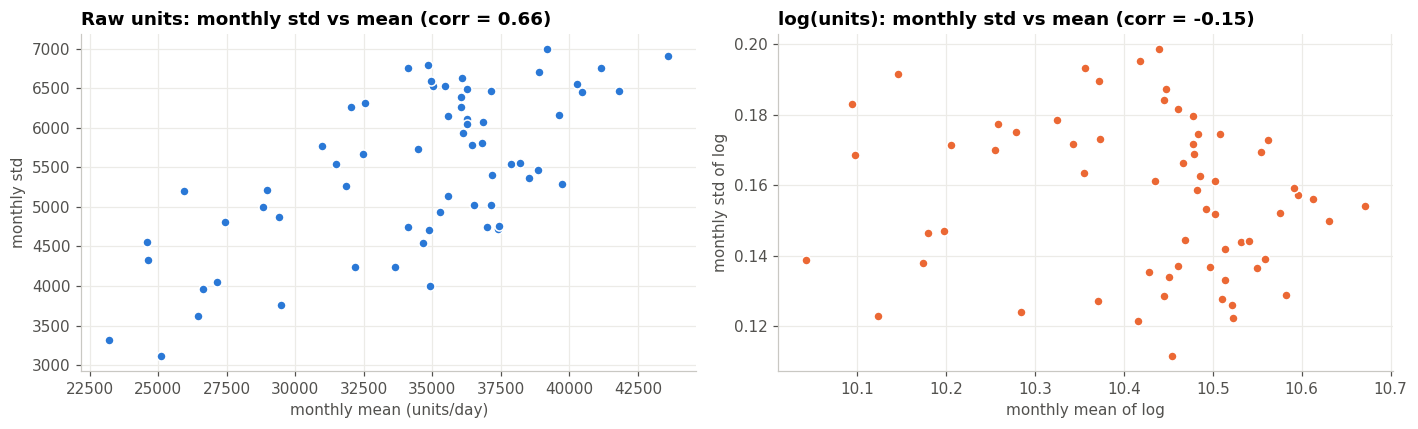

In [3]:
# For each month: average level and size of the daily wiggles (standard deviation)
tbl_month_stats = pd.DataFrame({
    "raw mean": ts_train.resample("MS").mean(),
    "raw std": ts_train.resample("MS").std(),
    "log mean": np.log(ts_train).resample("MS").mean(),
    "log std": np.log(ts_train).resample("MS").std(),
})
corr_raw = tbl_month_stats["raw mean"].corr(tbl_month_stats["raw std"])
corr_log = tbl_month_stats["log mean"].corr(tbl_month_stats["log std"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(tbl_month_stats["raw mean"], tbl_month_stats["raw std"], color=BLUE, s=35, edgecolor="white")
axes[0].set_title(f"Raw units: monthly std vs mean (corr = {corr_raw:.2f})")
axes[0].set_xlabel("monthly mean (units/day)"); axes[0].set_ylabel("monthly std")
axes[1].scatter(tbl_month_stats["log mean"], tbl_month_stats["log std"], color=ORANGE, s=35, edgecolor="white")
axes[1].set_title(f"log(units): monthly std vs mean (corr = {corr_log:.2f})")
axes[1].set_xlabel("monthly mean of log"); axes[1].set_ylabel("monthly std of log")
plt.tight_layout(); plt.show()

In [4]:
# A second opinion: the Box-Cox method finds the "best" power transformation automatically.
# lambda = 1 -> no transformation, lambda = 0.5 -> square root, lambda = 0 -> log.
lambdas = {}
for col in ["total", "state_CA", "state_TX", "state_WI"]:
    ts_col_train = fix_christmas(df_daily_agg[col])[~is_test]
    _, lam = stats.boxcox(ts_col_train.values)
    lambdas[col] = round(lam, 2)

tbl_boxcox = pd.DataFrame({"Box-Cox lambda": lambdas})
tbl_boxcox["closest simple transform"] = ["log (0)" if l < 0.25 else "sqrt (0.5) / log" if l < 0.75 else "none (1)"
                                          for l in tbl_boxcox["Box-Cox lambda"]]
tbl_boxcox

,Box-Cox lambda,closest simple transform
total,0.42,sqrt (0.5) / log
state_CA,0.24,log (0)
state_TX,0.36,sqrt (0.5) / log
state_WI,0.39,sqrt (0.5) / log


**What I see**

- **Raw units:** months with higher sales also have bigger wiggles (correlation ≈ 0.66). The variance grows with the level, so condition 2 is broken.
- **After log:** the link disappears (correlation ≈ −0.15, basically no relation). The log stabilises the variance.
- **Box-Cox** suggests λ between 0.24 (CA) and 0.42 (total), i.e. somewhere between a log (0) and a square root (0.5). It does not say "no transformation" (1) for any series.

**Decision: I model `log(sales)`.** It is close to what Box-Cox suggests, and it is much easier to explain: a coefficient on the log scale reads as a **% effect**, which fits the "weekend = +20 %" finding from notebook 01. Box-Cox with λ ≈ 0.4 stays as a robustness check for notebook 03 if I have time.

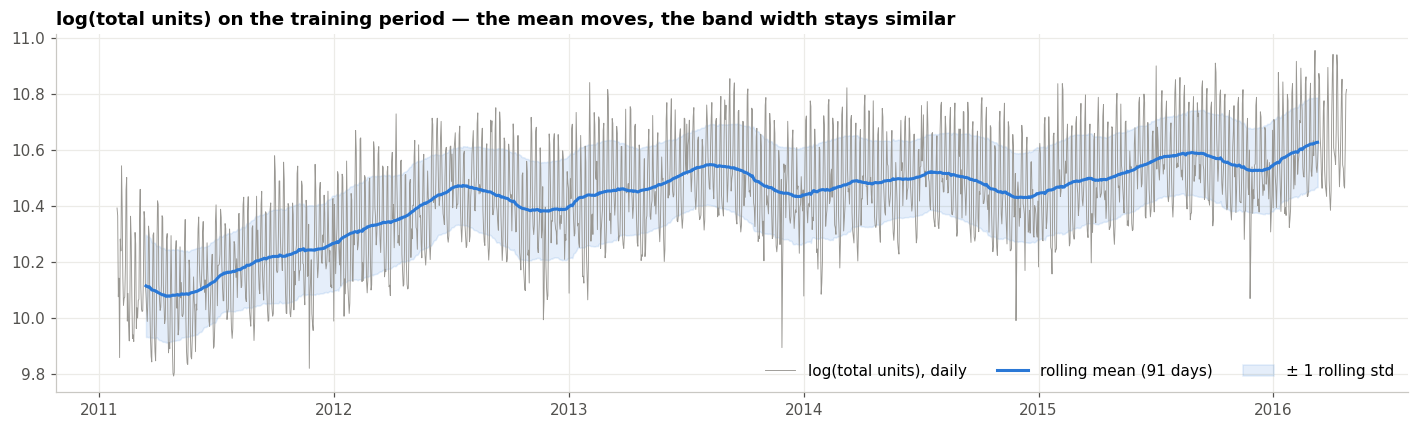

In [5]:
# From now on I work with the log of the training series
y_train = np.log(ts_train)
y_train.name = "log(total units)"

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(y_train.index, y_train, color=GREY, lw=0.6, label="log(total units), daily")
ax.plot(y_train.index, y_train.rolling(91, center=True).mean(), color=BLUE, lw=2, label="rolling mean (91 days)")
ax2_std = y_train.rolling(91, center=True).std()
ax.fill_between(y_train.index, y_train.rolling(91, center=True).mean() - ax2_std,
                y_train.rolling(91, center=True).mean() + ax2_std, color=BLUE, alpha=0.12, label="± 1 rolling std")
ax.set_title("log(total units) on the training period — the mean moves, the band width stays similar")
ax.legend(loc="lower right", ncol=3)
plt.tight_layout(); plt.show()

**Reading the chart:** after the log, the **width of the blue band** (the size of the wiggles) is roughly constant: good. But the **centre line** (the mean) still climbs, so condition 1 (constant mean) is still broken. That's what differencing will fix. First, though, I confirm it with formal tests.

## 3 · Formal tests: ADF and KPSS

My eyes say "not stationary", but in a report I need a test. There are two classic ones, and they ask the question **in opposite directions**:

| Test | H₀ (what it assumes until proven wrong) | Small p-value (< 0.05) means… |
|---|---|---|
| **ADF** (*Augmented Dickey–Fuller*) | the series has a **unit root** = it is **NOT** stationary | → reject H₀ → **stationary** ✅ |
| **KPSS** (*Kwiatkowski–Phillips–Schmidt–Shin*) | the series **IS** stationary | → reject H₀ → **NOT stationary** ❌ |

**Plain-English analogy:** ADF is a judge who assumes "guilty (non-stationary) until proven innocent", KPSS assumes "innocent until proven guilty". Using both is safer than trusting one:

| ADF says | KPSS says | My conclusion |
|---|---|---|
| stationary | stationary | ✅ stationary |
| not stationary | not stationary | ❌ not stationary → difference |
| stationary | not stationary | ⚠️ conflict → usually still difference (or remove a deterministic trend) |
| not stationary | stationary | ⚠️ conflict → test has low power, look at the plots |

(A **unit root** means a shock never dies out: if sales jump today, the series "remembers" it forever, like a random walk. Differencing removes that memory.)

In [6]:
def run_stationarity_tests(series, name):
    # Run ADF and KPSS on one series and return one row of a summary table.
    series = series.dropna()

    # ADF: H0 = unit root (NOT stationary). autolag="AIC" lets the test pick how many lags to include.
    adf_stat, adf_p, adf_lags, *_ = adfuller(series, autolag="AIC")

    # KPSS: H0 = stationary (around a constant mean, regression="c").
    # Note: statsmodels only reports p-values between 0.01 and 0.10, so 0.01 means "<= 0.01" and 0.10 means ">= 0.10".
    # It warns every time the true p-value is outside that range -> I silence that warning here.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kpss_stat, kpss_p, *_ = kpss(series, regression="c", nlags="auto")

    adf_says = "stationary" if adf_p < 0.05 else "NOT stationary"
    kpss_says = "stationary" if kpss_p > 0.05 else "NOT stationary"
    if adf_says == kpss_says == "stationary":
        verdict = "✅ stationary"
    elif adf_says == kpss_says == "NOT stationary":
        verdict = "❌ not stationary"
    else:
        verdict = "⚠️ tests disagree"

    return {"series": name, "ADF p-value": round(adf_p, 4), "ADF says": adf_says,
            "KPSS p-value": round(kpss_p, 3), "KPSS says": kpss_says, "verdict": verdict}


tbl_level_tests = pd.DataFrame([
    run_stationarity_tests(y_train, "log(total), Christmas fixed"),
    run_stationarity_tests(np.log(df_daily_agg["total"][~is_test].clip(lower=1)), "log(total), Christmas NOT fixed"),
]).set_index("series")
tbl_level_tests

,ADF p-value,ADF says,KPSS p-value,KPSS says,verdict
series,,,,,
"log(total), Christmas fixed",0.4616,NOT stationary,0.01,NOT stationary,❌ not stationary
"log(total), Christmas NOT fixed",0.0005,stationary,0.01,NOT stationary,⚠️ tests disagree


**What I see**

- On the clean log series, **both tests agree: not stationary** (ADF p ≈ 0.46, KPSS p ≤ 0.01). This confirms the chart: I need to difference.
- **The second row is a warning about outliers:** with the 5 Christmas days left in, ADF suddenly says "stationary" (p ≈ 0.0005) and the two tests now disagree. The huge one-day drops look like "the series quickly comes back to its mean", which fools the test. That's why cleaning Christmas *before* testing matters, and it's a good example for the report of how one data problem can flip a test result.

## 4 · Which differencing? → `d` and `D`

**Differencing** = instead of modelling the sales themselves, I model **how they change**. Two kinds:

| Name | Formula | Plain English | Removes |
|---|---|---|---|
| first difference, `d = 1` | $\Delta y_t = y_t - y_{t-1}$ | today − yesterday | the trend (wandering level) |
| seasonal difference, `D = 1`, `s = 7` | $\Delta_7 y_t = y_t - y_{t-7}$ | today − same weekday last week | the weekly pattern **and** most of a slow trend |
| both | $\Delta\Delta_7 y_t = (y_t - y_{t-7}) - (y_{t-1} - y_{t-8})$ | change of the weekly change | both |

Because I work on **log** sales, a difference is (approximately) a **% change**: $\log(y_t) - \log(y_{t-7}) \approx$ "growth vs last week's same day".

I try all three options and compare them with the tests + 2 simple diagnostics:
- **standard deviation**: a good rule of thumb (Hyndman & Athanasopoulos) is that the right amount of differencing usually gives the **smallest** std. Differencing *too much* adds noise back, and the std goes up again (this is called **over-differencing**).
- **ACF at lag 1 and lag 7**: if lag 7 is still very high, the weekly pattern is still there. If lag 1 is strongly negative (around −0.5), that's a typical sign of over-differencing.

In [7]:
# The 3 candidate transformations of y_train (all on the log scale)
dict_diff = {
    "d=1 (today - yesterday)": y_train.diff(1),
    "D=1, s=7 (today - last week)": y_train.diff(7),
    "d=1 + D=1 (both)": y_train.diff(7).diff(1),
}

rows = []
for name, z in dict_diff.items():
    row = run_stationarity_tests(z, name)
    acf_values = acf(z.dropna(), nlags=14)
    row["std"] = round(z.std(), 4)
    row["ACF lag 1"] = round(acf_values[1], 2)
    row["ACF lag 7"] = round(acf_values[7], 2)
    row["ACF lag 14"] = round(acf_values[14], 2)
    rows.append(row)

tbl_diff_options = pd.DataFrame(rows).set_index("series")
# I also add the undifferenced log series as the reference line
ref = run_stationarity_tests(y_train, "no differencing (log level)")
ref.update({"std": round(y_train.std(), 4), "ACF lag 1": round(acf(y_train, nlags=14)[1], 2),
            "ACF lag 7": round(acf(y_train, nlags=14)[7], 2), "ACF lag 14": round(acf(y_train, nlags=14)[14], 2)})
tbl_diff_options = pd.concat([pd.DataFrame([ref]).set_index("series"), tbl_diff_options])
tbl_diff_options[["verdict", "ADF p-value", "KPSS p-value", "std", "ACF lag 1", "ACF lag 7", "ACF lag 14"]]

,verdict,ADF p-value,KPSS p-value,std,ACF lag 1,ACF lag 7,ACF lag 14
series,,,,,,,
no differencing (log level),❌ not stationary,0.4616,0.01,0.2110,0.74,0.84,0.77
d=1 (today - yesterday),✅ stationary,0.0000,0.10,0.1522,0.16,0.68,0.69
"D=1, s=7 (today - last week)",✅ stationary,0.0000,0.10,0.1180,0.47,-0.30,-0.29
d=1 + D=1 (both),✅ stationary,0.0000,0.10,0.1210,-0.36,-0.51,0.02


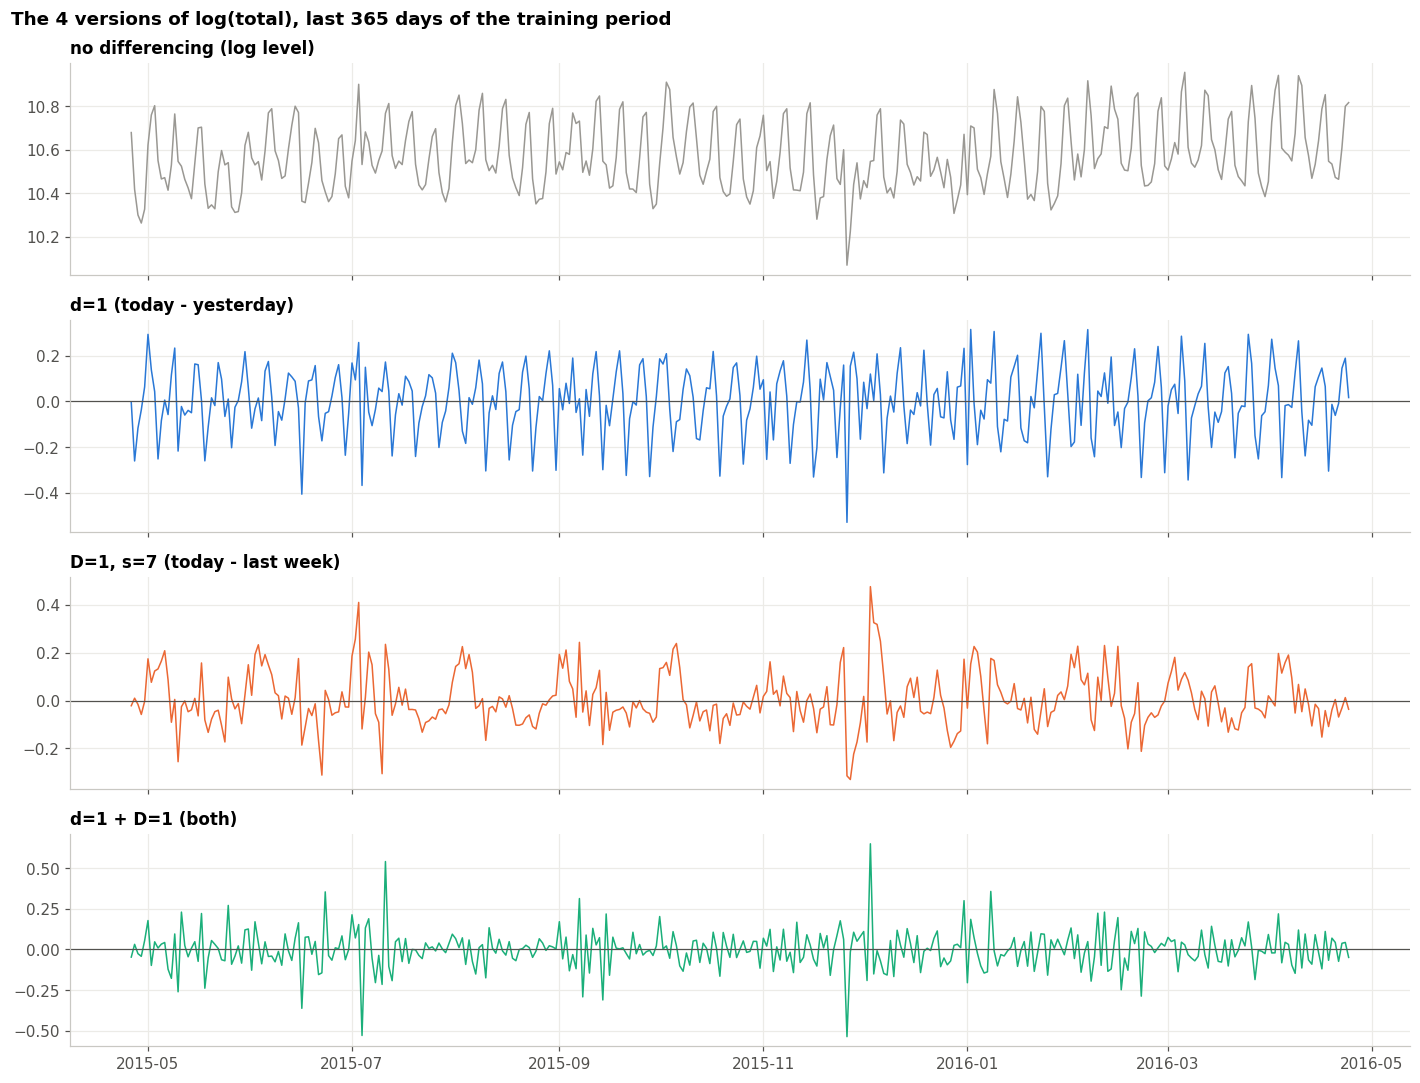

In [8]:
# What does each option look like? I show the last 365 training days so the detail is visible.
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
panels = [("no differencing (log level)", y_train)] + list(dict_diff.items())
colors = [GREY, BLUE, ORANGE, AQUA]
for ax, (name, z), color in zip(axes, panels, colors):
    z_last_year = z[-365:]
    ax.plot(z_last_year.index, z_last_year, color=color, lw=1)
    if name != "no differencing (log level)":
        ax.axhline(0, color=INK2, lw=0.8)
    ax.set_title(name, fontsize=11)
fig.suptitle("The 4 versions of log(total), last 365 days of the training period", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**What I see — this is the key table of the notebook**

| Option | Stationary? | Weekly pattern gone? | Comment |
|---|---|---|---|
| no differencing | ❌ | ❌ (ACF lag 7 ≈ 0.8) | trend + season still there |
| `d = 1` only | ✅ by the tests… | ❌ **ACF at lag 7 ≈ +0.68, lag 14 ≈ +0.69** | the tests say stationary, but the weekly pattern is fully alive. The chart (blue) still shows a clear weekly saw-tooth. **Not enough.** |
| `D = 1` only | ✅ | ✅ | **lowest std (0.118)**. ACF lag 1 ≈ +0.47 is positive memory, which ARMA can model. |
| `d = 1` + `D = 1` | ✅ | ✅ | std slightly **higher** (0.121) and ACF lag 1 ≈ −0.36: a mild sign of over-differencing, **or** simply an MA(1) term. |

**Lesson for the report:** "the ADF test says stationary" is **not** enough on its own. With `d = 1` alone the tests pass, but the strong seasonality is still in the data. Always check the ACF too.

**Decision: `D = 1` with `s = 7` for sure.** For `d` there are **two defensible routes**, and I keep both:

- **Route A — `d = 0, D = 1`**: lowest variance. A slow trend left after the seasonal difference shows up as a small constant (the average weekly growth rate), so this route needs a **constant / drift** term.
- **Route B — `d = 1, D = 1`**: the classic choice for trending seasonal series (it gives the famous "airline model"). It's more flexible if the trend changes speed, which it does (notebook 01: growth → flat → growth).

I can't choose between them with AIC, because **AIC values are not comparable between models with different differencing**: they are computed on different data (`Δ₇y` vs `ΔΔ₇y`). I'll compare them in notebook 03 on the **test set** (forecast error), which is fair for both.

## 5 · Reading the ACF and PACF → `p, q, P, Q`

Now that the series is stationary, I look at its "memory" with two plots.

- **ACF** (*autocorrelation function*): correlation between today and *k* days ago, **including** everything that happened in between. ("How similar is today to 3 days ago?", even if it's only because both are similar to the days between them.)
- **PACF** (*partial* ACF): correlation between today and *k* days ago **after removing** the effect of the days in between. ("Does 3 days ago still tell me something new, once I already know the last 2 days?")

The blue band is the ±1.96/√n zone: bars inside it are **not significantly different from 0**.

### The reading rules (Box–Jenkins)

| Pattern | ACF | PACF | Suggests |
|---|---|---|---|
| **AR(p)** — "today depends on the last p days" | decays slowly (geometric) | **cuts off** after lag p | `p` = last significant PACF lag |
| **MA(q)** — "today depends on the last q surprises" | **cuts off** after lag q | decays slowly | `q` = last significant ACF lag |
| **ARMA** | decays | decays | small p and q, decided by AIC |

**For the seasonal part**, same rules, but I only look at the **seasonal lags 7, 14, 21, 28…** (orange bars below):

| Seasonal lags 7, 14, 21… | ACF | PACF | Suggests |
|---|---|---|---|
| **Seasonal AR(P)** | decays over 7, 14, 21… | cuts off after lag 7·P | `P` |
| **Seasonal MA(Q)** | single spike at 7, then nothing | decays over 7, 14, 21… | `Q` |

In [9]:
def plot_acf_pacf(z, title, n_lags=42):
    # My own ACF / PACF plot: seasonal lags (7, 14, 21...) in orange so I can read the two parts separately.
    z = z.dropna()
    acf_values = acf(z, nlags=n_lags)
    pacf_values = pacf(z, nlags=n_lags, method="ywm")
    bound = 1.96 / np.sqrt(len(z))                       # significance band

    lags = np.arange(1, n_lags + 1)                       # I skip lag 0 (always = 1, useless)
    colors = [ORANGE if lag % 7 == 0 else BLUE for lag in lags]

    fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
    for ax, values, name in [(axes[0], acf_values, "ACF"), (axes[1], pacf_values, "PACF")]:
        ax.bar(lags, values[1:], color=colors, width=0.6)
        ax.axhspan(-bound, bound, color=BLUE, alpha=0.10)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xticks(range(0, n_lags + 1, 7))
        ax.set_xlabel("lag (days) — orange = seasonal lags 7, 14, 21…")
        ax.set_title(f"{name} — {title}", fontsize=11)
    axes[0].set_ylim(-0.7, 0.7)
    plt.tight_layout(); plt.show()

    # I also return the key numbers as a small table, so I don't have to read bar heights with my eyes
    key_lags = [1, 2, 3, 4, 5, 6, 7, 8, 14, 21, 28]
    return pd.DataFrame({"ACF": acf_values[key_lags].round(2), "PACF": pacf_values[key_lags].round(2)},
                        index=[f"lag {k}" for k in key_lags]).T

### 5.1 Route A — `D = 1` only: $\Delta_7 \log(y_t)$

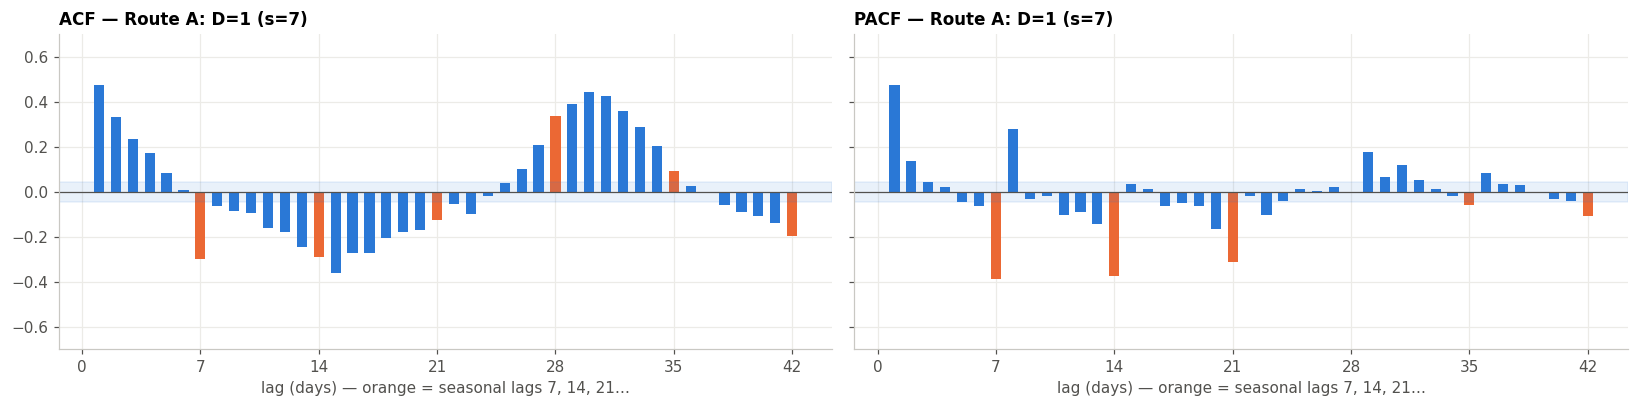

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 14,lag 21,lag 28
ACF,0.47,0.33,0.24,0.17,0.08,0.01,-0.30,-0.06,-0.29,-0.13,0.34
PACF,0.47,0.14,0.04,0.02,-0.05,-0.06,-0.39,0.28,-0.37,-0.31,-0.00


In [10]:
z_route_a = y_train.diff(7)
tbl_acf_route_a = plot_acf_pacf(z_route_a, "Route A: D=1 (s=7)")
tbl_acf_route_a

**Reading Route A**

*Non-seasonal part (blue bars, lags 1–6):*
- ACF **decays slowly**: 0.47 → 0.33 → 0.24 → 0.17 → 0.08…
- PACF has a big bar at lag 1 (0.47), a smaller one at lag 2 (0.14), then ≈ 0.
- → This is the **AR signature**: "today's weekly growth looks like yesterday's weekly growth". → **`p = 1`** (maybe 2), **`q = 0`**.

*Seasonal part (orange bars, lags 7, 14, 21, 28):*
- ACF: a clear **negative spike at lag 7** (−0.30).
- PACF: negative at 7, 14 **and** 21 (−0.39, −0.37, −0.31), slowly fading.
- → ACF spike + PACF decaying at seasonal lags = **seasonal MA**. → **`Q = 1`, `P = 0`**.

(Intuition for the seasonal MA: when one week is unusually high, the seasonal difference "today − last week" is high this week and *low* next week, because next week is compared with that unusual week. That creates the negative correlation at lag 7, and an MA term at lag 7 corrects it.)

**Route A candidate: `SARIMA(1, 0, 0)(0, 1, 1)₇` + constant**, with neighbours `(2,0,0)(0,1,1)₇` and `(1,0,1)(0,1,1)₇` to check in notebook 03.

### 5.2 Route B — `d = 1` and `D = 1`: $\Delta\Delta_7 \log(y_t)$

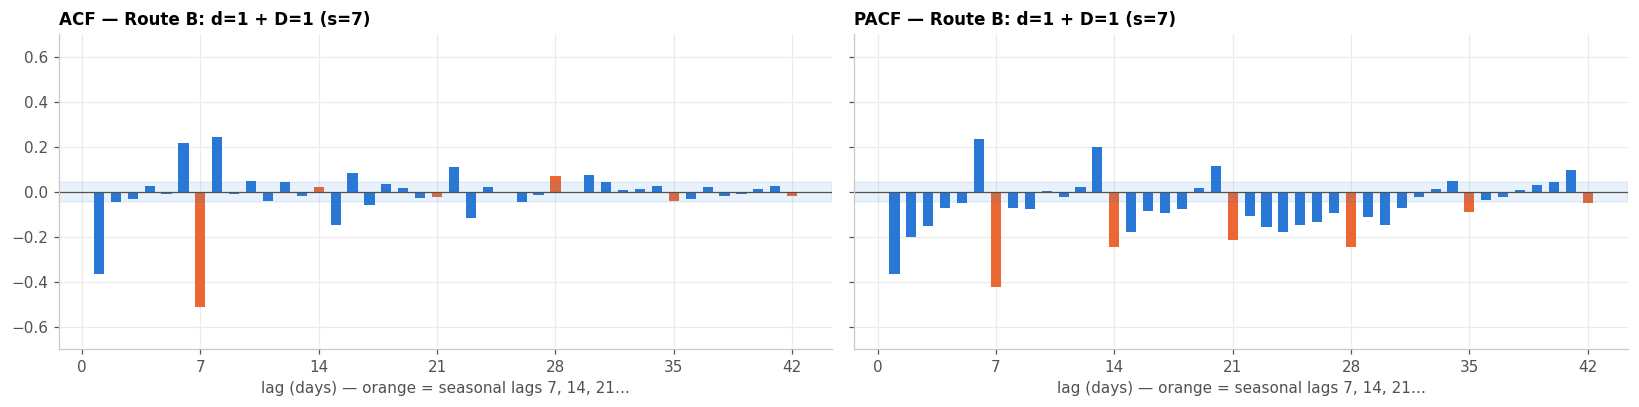

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 14,lag 21,lag 28
ACF,-0.36,-0.04,-0.03,0.02,-0.01,0.22,-0.51,0.24,0.02,-0.03,0.07
PACF,-0.36,-0.20,-0.15,-0.07,-0.05,0.24,-0.42,-0.07,-0.24,-0.21,-0.24


In [11]:
z_route_b = y_train.diff(7).diff(1)
tbl_acf_route_b = plot_acf_pacf(z_route_b, "Route B: d=1 + D=1 (s=7)")
tbl_acf_route_b

**Reading Route B**

*Non-seasonal part (lags 1–6):*
- ACF: **one spike at lag 1** (−0.36), then lags 2–5 ≈ 0. It "cuts off".
- PACF: decays (−0.36 → −0.20 → −0.15 → −0.07).
- → **MA signature** → **`q = 1`, `p = 0`**.

*Seasonal part (lags 7, 14, 21):*
- ACF: **one big spike at lag 7** (−0.51), then ≈ 0 at 14, 21, 28.
- PACF: stays negative over 7, 14, 21, 28 (−0.42, −0.24, −0.21, −0.24), i.e. it does not cut off.
- → **Seasonal MA** → **`Q = 1`, `P = 0`**.

*The small positive bars at lags 6 and 8* (+0.22, +0.24) are **not** extra terms. They appear automatically when a non-seasonal MA(1) and a seasonal MA(1) are multiplied together, because (1 + θB)(1 + ΘB⁷) contains a B⁸ term. Seeing them is actually a confirmation.

**Route B candidate: `SARIMA(0, 1, 1)(0, 1, 1)₇`**. This is exactly the **"airline model"** of Box & Jenkins (originally for monthly airline passengers, with s = 12), the classic benchmark for trending seasonal data. Neighbours to check: `(1,1,1)(0,1,1)₇` and `(0,1,2)(0,1,1)₇`.

### 5.3 And a plain ARIMA (no seasonal part)?

My task also includes a **non-seasonal ARIMA**. It's useful as a step between the naive baselines and SARIMA, to *show* how much the seasonal terms help. With `d = 1` only, the ARIMA has to imitate the weekly cycle with ordinary AR lags:

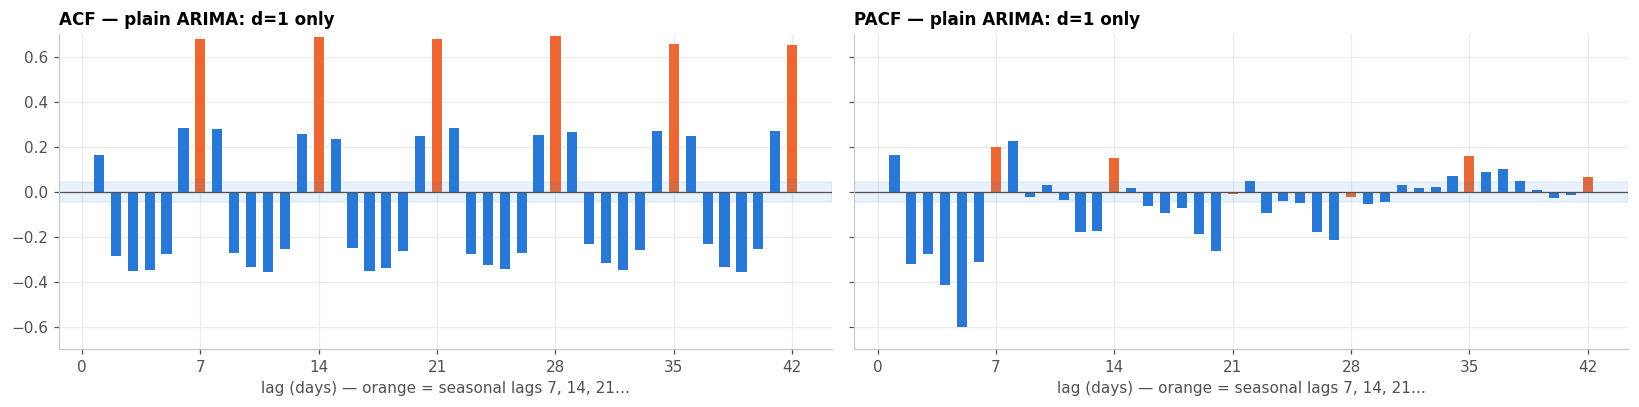

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8,lag 14,lag 21,lag 28
ACF,0.16,-0.29,-0.35,-0.35,-0.28,0.28,0.68,0.28,0.69,0.68,0.69
PACF,0.16,-0.32,-0.27,-0.41,-0.60,-0.31,0.20,0.23,0.15,-0.01,-0.02


In [12]:
z_arima = y_train.diff(1)
tbl_acf_arima = plot_acf_pacf(z_arima, "plain ARIMA: d=1 only")
tbl_acf_arima

**Reading the plain ARIMA case**

- The ACF has **huge orange bars at 7, 14, 21, 28, 35** (≈ +0.68 each) that **don't fade**. That's the weekly cycle, still completely there.
- The PACF is significant at **every lag from 1 to 8**.
- → To copy a 7-day cycle without seasonal terms, a plain ARIMA needs **at least 6–7 AR lags**: **`ARIMA(7, 1, 0)`** is the natural candidate (`ARIMA(6,1,1)` as a neighbour).

So I expect the plain ARIMA to be **worse and less parsimonious** (more parameters) than SARIMA. Showing that with numbers in notebook 03 is the whole point of including it.

## 6 · Do the 3 states follow the same recipe?

Before going further, I check that my conclusions are not specific to the total. I run the same tests and look at the same key ACF values for CA, TX and WI.

In [13]:
rows = []
for state in ["CA", "TX", "WI"]:
    y_state = np.log(fix_christmas(df_daily_agg[f"state_{state}"])[~is_test])
    options = {"log level": y_state, "d=1": y_state.diff(1), "D=1": y_state.diff(7), "d=1 + D=1": y_state.diff(7).diff(1)}
    for option_name, z in options.items():
        test_row = run_stationarity_tests(z, option_name)
        acf_values = acf(z.dropna(), nlags=7)
        rows.append({"state": state, "option": option_name, "verdict": test_row["verdict"],
                     "std": round(z.std(), 3), "ACF lag 1": round(acf_values[1], 2), "ACF lag 7": round(acf_values[7], 2)})

tbl_states = pd.DataFrame(rows).set_index(["state", "option"])
tbl_states

verdict    std  ACF lag 1  ACF lag 7
state option                                                  
CA    log level  ❌ not stationary  0.212       0.71       0.86
      d=1            ✅ stationary  0.161       0.18       0.71
      D=1            ✅ stationary  0.111       0.39      -0.41
      d=1 + D=1      ✅ stationary  0.122      -0.38      -0.52
TX    log level  ❌ not stationary  0.194       0.64       0.77
      d=1            ✅ stationary  0.165       0.01       0.52
      D=1            ✅ stationary  0.131       0.24      -0.37
      d=1 + D=1      ✅ stationary  0.161      -0.53      -0.57
WI    log level  ❌ not stationary  0.273       0.76       0.75
      d=1            ✅ stationary  0.187      -0.04       0.43
      D=1            ✅ stationary  0.191       0.47      -0.27
      d=1 + D=1      ✅ stationary  0.197      -0.36      -0.48

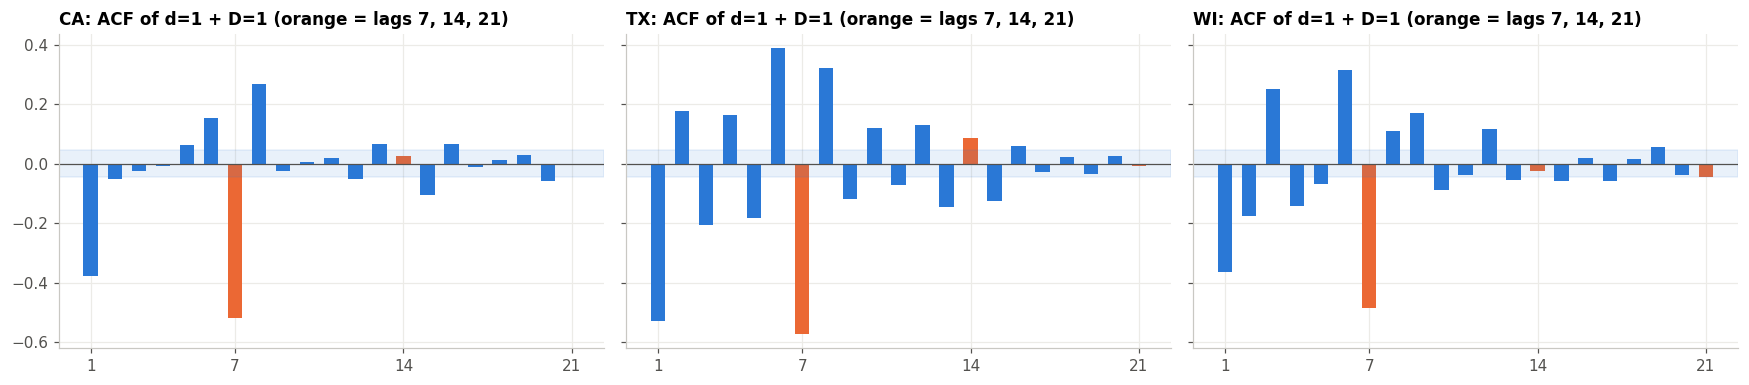

In [14]:
# Side by side: the Route B ACF for the 3 states (lags 1-21)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, state in zip(axes, ["CA", "TX", "WI"]):
    y_state = np.log(fix_christmas(df_daily_agg[f"state_{state}"])[~is_test])
    z = y_state.diff(7).diff(1).dropna()
    acf_values = acf(z, nlags=21)
    lags = np.arange(1, 22)
    ax.bar(lags, acf_values[1:], color=[ORANGE if l % 7 == 0 else BLUE for l in lags], width=0.6)   # same colours as section 5
    bound = 1.96 / np.sqrt(len(z))
    ax.axhspan(-bound, bound, color=BLUE, alpha=0.10); ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks([1, 7, 14, 21]); ax.set_title(f"{state}: ACF of d=1 + D=1 (orange = lags 7, 14, 21)", fontsize=11)
plt.tight_layout(); plt.show()

**What I see**

- **Same picture in all 3 states:** the log level is not stationary, `d = 1` alone leaves a big ACF at lag 7 (+0.43 to +0.71), and both `D = 1` and `d = 1 + D = 1` are stationary.
- In **CA and TX**, `D = 1` alone again has the lowest std, like the total.
- **WI is the exception:** `d = 1` has the lowest std (0.187), and the seasonal difference doesn't reduce the noise much. That fits notebook 01 (WI has the weakest weekly pattern and structural breaks in WI_1 / WI_2). The ACF at lag 7 after `d = 1` is still +0.43, though, so the seasonal part is still needed.
- **Route B ACF:** the airline signature (spike at 1, spike at 7) appears in all 3. **TX** has extra structure (lag 1 = −0.53 and alternating signs at lags 2–6), so it may need one more term, e.g. `(1,1,1)(0,1,1)₇`.

**Conclusion:** the same candidate families work for all 3 states. I'll fit the total first, then reuse the code for the states.

## 7 · Summary — candidate models for notebook 03

| Model family | Transformation | Differencing | Main candidate | Neighbours to test | Why |
|---|---|---|---|---|---|
| Plain ARIMA | log | `d = 1` | `ARIMA(7, 1, 0)` | `ARIMA(6,1,1)` | §5.3: PACF significant up to lag 7–8, weekly cycle not removed |
| **SARIMA — Route A** | log | `d = 0, D = 1, s = 7` + constant | `SARIMA(1,0,0)(0,1,1)₇` | `(2,0,0)(0,1,1)₇`, `(1,0,1)(0,1,1)₇` | §5.1: AR(1) decay + seasonal MA spike at 7 |
| **SARIMA — Route B** | log | `d = 1, D = 1, s = 7` | `SARIMA(0,1,1)(0,1,1)₇` (airline) | `(1,1,1)(0,1,1)₇`, `(0,1,2)(0,1,1)₇` | §5.2: MA(1) spike + seasonal MA spike + side lobes at 6 and 8 |

### How I'll choose in notebook 03

1. **Within** each family (same `d` and `D`): compare candidates with **AIC** (lower = better trade-off between fit and number of parameters).
2. **Residual check** on each winner: residuals should look like white noise. **Ljung–Box test** (H₀: no autocorrelation left; I want a large p-value) + ACF of residuals.
3. **Between** families (different `d`): compare the **28-day forecast error on the locked test set** (RMSE, MAPE, and MASE / RMSSE against the seasonal-naive baseline). That's the only fair comparison across different differencing.
4. Baselines to beat: **naive** (tomorrow = today) and **seasonal naive** (same day last week).

The cell below saves this list so notebook 03 can read it directly.

In [15]:
candidate_orders = {
    "ARIMA":         {"main": [[7, 1, 0], [0, 0, 0, 0]], "neighbours": [[[6, 1, 1], [0, 0, 0, 0]]], "trend": "n"},
    "SARIMA_routeA": {"main": [[1, 0, 0], [0, 1, 1, 7]], "neighbours": [[[2, 0, 0], [0, 1, 1, 7]], [[1, 0, 1], [0, 1, 1, 7]]], "trend": "c"},
    "SARIMA_routeB": {"main": [[0, 1, 1], [0, 1, 1, 7]], "neighbours": [[[1, 1, 1], [0, 1, 1, 7]], [[0, 1, 2], [0, 1, 1, 7]]], "trend": "n"},
    "settings": {"transform": "log", "series": "total (Christmas fixed)",
                 "train_end": str(ts_train.index[-1].date()), "test_start": str(ts_test.index[0].date()), "horizon": 28},
}
with open(DATA_DIR / "candidate_orders.json", "w") as f:
    json.dump(candidate_orders, f, indent=2)
print("Saved:", DATA_DIR / "candidate_orders.json")
pd.DataFrame({k: v["main"] for k, v in candidate_orders.items() if k != "settings"}, index=["(p,d,q)", "(P,D,Q,s)"])

Saved: data_processed/candidate_orders.json


,ARIMA,SARIMA_routeA,SARIMA_routeB
"(p,d,q)","[7, 1, 0]","[1, 0, 0]","[0, 1, 1]"
"(P,D,Q,s)","[0, 0, 0, 0]","[0, 1, 1, 7]","[0, 1, 1, 7]"
